# FIN 6465 — Chapter 1 Mini-Project
## From NPV to Enterprise Value: A Mini-DCF Notebook

**Financial Modeling with Python — Chapter 1: Introduction to Financial Modeling**

> **Guiding question:** How sensitive is a simple DCF value to its key assumptions, and what would you need from a company's financial statements to make its free cash flows defensible?


### Student information

| | |
|---|---|
| **Name** | *Sophia Parra* |
| **UF email** | *Sophiaparra@ufl.edu* |
| **Section** | *R222 (4:05 PM)* |
| **Team members** | *Aman Vyas, Caleb D'Antonio, Casey Brigid* |
| **Team company (ticker)** | * Quanta Services (PWR)* |
| **Generative AI tools used** | * Claude (details in the AI-use reflection)* |


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.12.8
NumPy      1.26.4
pandas     2.2.2
Matplotlib 3.9.2


In [2]:
import os, json
from pathlib import Path
from getpass import getpass
import requests

FMP_BASE = "https://financialmodelingprep.com/stable"
CACHE_DIR = Path("fmp_cache")
CACHE_DIR.mkdir(exist_ok=True)

FMP_API_KEY = os.environ.get("FMP_API_KEY") or getpass("Paste your team's FMP API key (input is hidden): ")


def fmp_get(endpoint, symbol, period="annual", limit=5, use_cache=True):
    """Fetch one FMP endpoint for a ticker and return a DataFrame (most recent period first).

    endpoint : "income-statement", "balance-sheet-statement", or "cash-flow-statement"
    symbol   : ticker, e.g. "AAPL"
    period   : "annual" (10-K) or "quarter" (10-Q)
    limit    : number of periods to return
    """
    symbol = symbol.upper().strip()
    cache_file = CACHE_DIR / f"{symbol}_{endpoint}_{period}_{limit}.json"
    if use_cache and cache_file.exists():
        data = json.loads(cache_file.read_text())
    else:
        params = {"symbol": symbol, "period": period, "limit": limit, "apikey": FMP_API_KEY}
        response = requests.get(f"{FMP_BASE}/{endpoint}", params=params, timeout=30)
        if response.status_code != 200:
            raise RuntimeError(f"FMP returned HTTP {response.status_code}: {response.text[:300]}")
        data = response.json()
        if isinstance(data, dict):   # FMP reports problems as a JSON object
            raise RuntimeError(f"FMP error for {symbol}: {data}")
        if not data:
            raise ValueError(f"No data returned for {symbol} ({endpoint}). Check the ticker.")
        cache_file.write_text(json.dumps(data))
    return pd.DataFrame(data)


def pick(df, field, row=0):
    """Return one value from an FMP statement: `field` in row `row` (0 = most recent year)."""
    if field not in df.columns:
        raise KeyError(f"'{field}' is not a column. Look at df.columns to find the right field name.")
    value = df.iloc[row][field]
    if pd.isna(value):
        raise ValueError(f"'{field}' is empty for row {row}. Check the 10-K and choose another field.")
    return float(value)

print("FMP helper ready. API key loaded:", bool(FMP_API_KEY))

FMP helper ready. API key loaded: True


In [3]:
# ===================== ASSUMPTIONS =====================
UNITS = "USD thousands"          # state the units used for every cash flow below

# --- NPV test case from Chapter 1 (do not change) ---
TEST_CASH_FLOWS = [-400, 100, 150, 200, 250]   # t = 0, 1, 2, 3, 4
TEST_RATE = 0.08
TEST_NPV_EXPECTED = 163.72                       # from the brief (rounded)

# --- Mini-DCF inputs (your illustrative forecast) ---
FCF_FORECAST = [120, 130, 140, 150, 160]        # TODO: five annual FCFs for years 1-5, e.g. [120, 130, 140, 150, 160]
DISCOUNT_RATE = 0.085     # TODO: base-case discount rate, e.g. 0.085
TERMINAL_GROWTH = 0.025   # TODO: base-case terminal growth rate, e.g. 0.025

# --- Company data (Section 2.6) ---
SYMBOL = "PWR"              # TODO: your team's S&P 500 ticker, e.g. "MSFT"
SCALE = 1e6              # FMP reports whole dollars; divide by SCALE for USD millions
FCFF_UNITS = "USD millions"

# --- Sensitivity ranges (from the brief) ---
SENS_RATES = [0.07, 0.08, 0.09, 0.10]
SENS_GROWTH = [0.02, 0.03, 0.04]

# --- Validation thresholds ---
TV_SHARE_FLAG = 0.75     # flag if terminal value exceeds this share of EV
TOLERANCE = 1e-6         # agreement tolerance between NPV methods

---
## 2.2 Net Present Value


In [4]:
def calculate_npv(cash_flows, discount_rate):
    """Return the net present value of a list of cash flows.

    Parameters
    ----------
    cash_flows : list of float
        Cash flows at t = 0, 1, 2, ... (t = 0 is today; outflows negative).
    discount_rate : float
        Per-period discount rate as a decimal (0.08 = 8%), matching the cash-flow frequency.

    Returns
    -------
    float
    """
    npv = 0.0
    for t, cf in enumerate(cash_flows):     # t = 0, 1, 2, ...
        npv += cf / (1 + discount_rate) ** t
    return npv

In [5]:
npv_loop = calculate_npv(TEST_CASH_FLOWS, TEST_RATE)
print(f"NPV (loop) at {TEST_RATE:.0%}: {npv_loop:,.2f} {UNITS}")
assert abs(npv_loop - TEST_NPV_EXPECTED) < 0.01, "NPV does not match the Chapter 1 example"

NPV (loop) at 8%: 163.72 USD thousands


**Confirm with a vectorized calculation.** Compute the same NPV with NumPy arrays instead of a loop; the two results should match.

In [6]:
cf = np.array(TEST_CASH_FLOWS, dtype=float)   # cash flows as an array
t = np.arange(len(cf))                         # 0, 1, 2, 3, 4

npv_vectorized = np.sum(cf / (1 + TEST_RATE) ** t)

print(f"NPV (vectorized): {npv_vectorized:,.2f} {UNITS}")
print(f"Difference vs. loop: {abs(npv_loop - npv_vectorized):.2e}")

NPV (vectorized): 163.72 USD thousands
Difference vs. loop: 0.00e+00


✍️ **Interpretation (1–2 sentences):** Does this project create or destroy value at an 8% required return? Why?

*The project creates value because at an 8% required return the NPV is positive 163.72 thousand USD. For a value creating project we are looking for the NPV to be greater than zero, in this case the future cashflows are worth 163.72 thousand more than the initial 400 thousand cost.*

---
## 2.3 Visualizing Cash Flows


,year,cash_flow,discount_factor,present_value
0,0,-400,1.000,-400.000
1,1,100,0.926,92.593
2,2,150,0.857,128.601
3,3,200,0.794,158.766
4,4,250,0.735,183.757


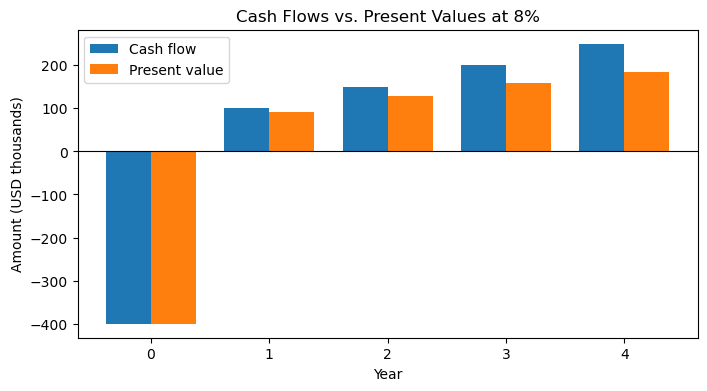

In [7]:
years = np.arange(len(TEST_CASH_FLOWS))
cf_table = pd.DataFrame({"year": years, "cash_flow": TEST_CASH_FLOWS})

cf_table["discount_factor"] = 1 / (1 + TEST_RATE) ** cf_table["year"]  # 1 / (1 + r)^t for each year
cf_table["present_value"] = cf_table["cash_flow"] * cf_table["discount_factor"]
display(cf_table.round(3))

# Side-by-side bars: cash flow vs. present value 
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.38
ax.bar(years - w/2, cf_table["cash_flow"], w, label="Cash flow")
ax.bar(years + w/2, cf_table["present_value"], w, label="Present value")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Cash Flows vs. Present Values at 8%")
ax.set_xlabel("Year")
ax.set_ylabel(f"Amount ({UNITS})")
ax.legend()
plt.show()

---
## 2.4 Mini-DCF: From Free Cash Flow to Enterprise Value

$$
EV = \sum_{t=1}^{T} \frac{FCF_t}{(1+r)^t} + \frac{TV_T}{(1+r)^T}, \qquad TV_T = \frac{FCF_T(1+g)}{r-g}
$$


In [8]:
def enterprise_value_dcf(fcf_forecast, discount_rate, terminal_growth):
    """Simplified enterprise DCF with a Gordon growth terminal value.

    Parameters
    ----------
    fcf_forecast : list of float
        FCF for years 1..T (the first value is discounted one period).
    discount_rate : float
        Annual discount rate r (decimal).
    terminal_growth : float
        Long-run growth rate g (decimal); must be below r.

    Returns
    -------
    dict with keys: 'pv_fcf', 'terminal_value', 'pv_terminal', 'enterprise_value', 'tv_share'
    """
    r, g = discount_rate, terminal_growth
   
    assert r > g, f"Discount rate ({r}) must exceed terminal growth ({g})"
    # 1) Present value of the forecast-period FCFs (year 1 is discounted one period)
    pv_fcf = 0.0
    for t, fcf in enumerate(fcf_forecast, start=1):
        pass  # TODO: add the PV of this year's FCF to pv_fcf
        pv_fcf += fcf / (1 + r) ** t

    # 2) Terminal value at year T and its present value
    T = len(fcf_forecast)
    terminal_value = fcf_forecast[-1] * (1 + g) / (r - g)  
    pv_terminal = terminal_value / (1+r) ** T     

    # 3) Enterprise value and the terminal value's share of it
    enterprise_value = pv_fcf + pv_terminal 
    tv_share = pv_terminal / enterprise_value         

    return {"pv_fcf": pv_fcf, "terminal_value": terminal_value, "pv_terminal": pv_terminal,
            "enterprise_value": enterprise_value, "tv_share": tv_share}

In [9]:
base = enterprise_value_dcf(FCF_FORECAST, DISCOUNT_RATE, TERMINAL_GROWTH)

print(f"Base case: r = {DISCOUNT_RATE:.2%}, g = {TERMINAL_GROWTH:.2%}  ({UNITS})")
print(f"  PV of forecast FCF   {base['pv_fcf']:>12,.1f}")
print(f"  PV of terminal value {base['pv_terminal']:>12,.1f}")
print(f"  Enterprise value     {base['enterprise_value']:>12,.1f}")
print(f"  Terminal value share {base['tv_share']:>12.1%}")

Base case: r = 8.50%, g = 2.50%  (USD thousands)
  PV of forecast FCF          545.3
  PV of terminal value      1,817.8
  Enterprise value          2,363.1
  Terminal value share        76.9%


✍️ **Interpretation (2–3 sentences):** What share of EV comes from the terminal value, and what does that imply about which assumptions drive the valuation?

*76.9% of the EV comes from the terminal value which implies that the terminal value forecast is what is driving the valuation. This reinforces the importance of the terminal growth rate and discount rate as key assumptions because small changes in r-g can impact EV significantly.*

---
## 2.5 Sensitivity Analysis


Terminal growth g,2%,3%,4%
Discount rate r,,,
7%,2896.0,3506.0,4523.0
8%,2404.0,2796.0,3384.0
9%,2053.0,2323.0,2701.0
10%,1790.0,1985.0,2246.0


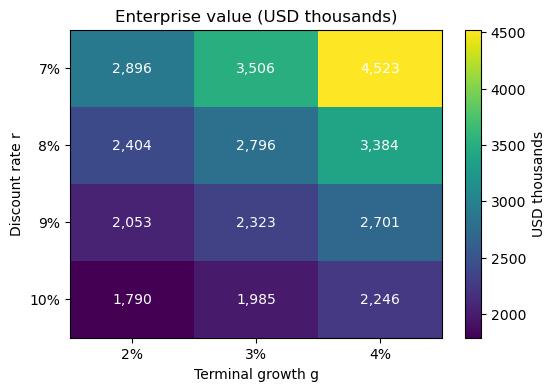

In [10]:
rows = []
for r in SENS_RATES:
    row = []
    for g in SENS_GROWTH:
        
        row.append(enterprise_value_dcf(FCF_FORECAST , r , g)["enterprise_value"])
    rows.append(row)

sens_table = pd.DataFrame(rows,
                          index=[f"{r:.0%}" for r in SENS_RATES],
                          columns=[f"{g:.0%}" for g in SENS_GROWTH])
sens_table.index.name = "Discount rate r"
sens_table.columns.name = "Terminal growth g"
display(sens_table.round(0))

# Heat map (provided)
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(sens_table.values.astype(float), cmap="viridis", aspect="auto")
ax.set_xticks(range(len(SENS_GROWTH)), sens_table.columns)
ax.set_yticks(range(len(SENS_RATES)), sens_table.index)
ax.set(xlabel="Terminal growth g", ylabel="Discount rate r", title=f"Enterprise value ({UNITS})")
for i in range(len(SENS_RATES)):
    for j in range(len(SENS_GROWTH)):
        ax.text(j, i, f"{sens_table.values[i, j]:,.0f}", ha="center", va="center", color="white")
fig.colorbar(im, ax=ax, label=UNITS)
plt.show()

✍️ **Interpretation (one short paragraph):** Over the tested ranges, which moves value more, $r$ or $g$? State the valuation as a **range**.

*In the sensitivity analysis, the discount rate moves the EV more. Going from 7% to 10% decreases EV by about 2.3 million while growth moves it up to about 1.6 million. Growth also matters the most when the discount rate is low because the spread between r and g is narrower so the valuation becomes more sensitive to those assumptions. EV ranges from 1.79 million to 4.5 million.*

---
## 2.6 Free Cash Flow from the Financial Statements

$$
FCFF_t = EBIT_t(1-\tau_t) + D\&A_t - CapEx_t - \Delta NWC_t
$$

### Step 1: Retrieve the statements

In [11]:
income   = fmp_get("income-statement", SYMBOL)
balance  = fmp_get("balance-sheet-statement", SYMBOL)
cashflow = fmp_get("cash-flow-statement", SYMBOL)

# Which filings did these come from?
source_cols = ["date", "fiscalYear", "period", "filingDate", "reportedCurrency"]
display(income[[c for c in source_cols if c in income.columns]])

,date,fiscalYear,period,filingDate,reportedCurrency
0,2025-12-31,2025,FY,2026-02-19,USD
1,2024-12-31,2024,FY,2025-02-20,USD
2,2023-12-31,2023,FY,2024-02-22,USD
3,2022-12-31,2022,FY,2023-02-23,USD
4,2021-12-31,2021,FY,2022-02-25,USD


### Step 2: Find the fields you need

| Input | Statement | FMP field(s) to look for |
|---|---|---|
| EBIT | income | `operatingIncome` (or `ebit`) |
| Tax rate | income | `incomeTaxExpense` ÷ `incomeBeforeTax` |
| D&A | cash flow | `depreciationAndAmortization` |
| CapEx | cash flow | `capitalExpenditure` |
| Operating NWC | balance | `totalCurrentAssets`, `cashAndShortTermInvestments`, `totalCurrentLiabilities`, `shortTermDebt` |
| Cash from operations | cash flow | `operatingCashFlow` (or `netCashProvidedByOperatingActivities`) |


In [12]:
print("Income statement fields:\n", list(income.columns), "\n")
print("Balance sheet fields:\n", list(balance.columns), "\n")
print("Cash flow fields:\n", list(cashflow.columns))

Income statement fields:
 ['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'revenue', 'costOfRevenue', 'grossProfit', 'researchAndDevelopmentExpenses', 'generalAndAdministrativeExpenses', 'sellingAndMarketingExpenses', 'sellingGeneralAndAdministrativeExpenses', 'otherExpenses', 'operatingExpenses', 'costAndExpenses', 'netInterestIncome', 'interestIncome', 'interestExpense', 'depreciationAndAmortization', 'ebitda', 'ebit', 'nonOperatingIncomeExcludingInterest', 'operatingIncome', 'totalOtherIncomeExpensesNet', 'incomeBeforeTax', 'incomeTaxExpense', 'netIncomeFromContinuingOperations', 'netIncomeFromDiscontinuedOperations', 'otherAdjustmentsToNetIncome', 'netIncome', 'netIncomeDeductions', 'bottomLineNetIncome', 'eps', 'epsDiluted', 'weightedAverageShsOut', 'weightedAverageShsOutDil'] 

Balance sheet fields:
 ['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'cashAndCashEquivalents', 'sho

### Step 3: Build the FCFF inputs (most recent fiscal year)


In [13]:
FISCAL_YEAR = income.iloc[0].get("fiscalYear", str(income.iloc[0]["date"])[:4])

def operating_nwc(row):
    """Operating NWC for one balance sheet row (0 = latest year, 1 = prior year), in USD millions."""
    current_assets_ex_cash = pick(balance, "totalCurrentAssets", row) - pick(balance, "cashAndShortTermInvestments", row)
    current_liab_ex_debt = pick(balance, "totalCurrentLiabilities", row) - pick(balance, "shortTermDebt", row)
    return (current_assets_ex_cash - current_liab_ex_debt) / SCALE


ebit     = pick(income, "operatingIncome") / SCALE
tax_rate = pick(income,"incomeTaxExpense") / pick(income,"incomeBeforeTax")
da       = pick(cashflow, "depreciationAndAmortization") / SCALE
capex    = -pick(cashflow,"capitalExpenditure") / SCALE      # positive amount: FMP reports it as negative
nwc_now  = operating_nwc(0)
nwc_prior = operating_nwc(1)
cfo      = pick(cashflow,"operatingCashFlow") / SCALE

fcff_inputs = pd.DataFrame([
    ["EBIT",                 ebit,      "IS", "operatingIncome"],
    ["Tax rate (tau)",       tax_rate,  "IS", "incomeTaxExpense / incomeBeforeTax"],
    ["D&A",                  da,        "CF", "depreciationAndAmortization"],
    ["CapEx",                capex,     "CF", "capitalExpenditure (sign flipped)"],
    ["NWC, current year",    nwc_now,   "BS", "operating NWC, row 0"],
    ["NWC, prior year",      nwc_prior, "BS", "operating NWC, row 1"],
    ["Cash from operations", cfo,       "CF", "operatingCashFlow"],
], columns=["input", "value", "statement", "fmp_field"]).set_index("input")
fcff_inputs

,value,statement,fmp_field
input,,,
EBIT,1637.141000,IS,operatingIncome
Tax rate (tau),0.261778,IS,incomeTaxExpense / incomeBeforeTax
D&A,910.333000,CF,depreciationAndAmortization
CapEx,609.154000,CF,capitalExpenditure (sign flipped)
"NWC, current year",1511.609000,BS,"operating NWC, row 0"
"NWC, prior year",1143.240000,BS,"operating NWC, row 1"
Cash from operations,2229.970000,CF,operatingCashFlow


In [14]:
v = fcff_inputs["value"]
delta_nwc = v["NWC, current year"] - v["NWC, prior year"]   # an increase in NWC uses cash


fcff = v["EBIT"]*(1-v["Tax rate (tau)"]) + v["D&A"] - v["CapEx"] - delta_nwc

cfo_less_capex = v["Cash from operations"] - v["CapEx"]

print(f"{SYMBOL}, FY{FISCAL_YEAR} ({FCFF_UNITS})")
print(f"  Change in NWC        {delta_nwc:>12,.1f}")
print(f"  FCFF                 {fcff:>12,.1f}")
print(f"  CFO - CapEx          {cfo_less_capex:>12,.1f}")
print(f"  Difference           {fcff - cfo_less_capex:>12,.1f}")

PWR, FY2025 (USD millions)
  Change in NWC               368.4
  FCFF                      1,141.4
  CFO - CapEx               1,620.8
  Difference                 -479.4


### Step 4: Verify against the 10-K

| Input checked | FMP value (USD millions) | 10-K value (USD millions) | 10-K statement and line item | Match? If not, why? |
|---|---|---|---|---|
| *Capex* | 609.15| 609.15 | Consolidated Statements of Cash Flows, Capital Expenditures | They both match most likely because there are no adjustments you can make to capex for the line item to vary, it is simply a disclosed figure that FMP pulls as is. FMP shows it as a negative so we flipped the sign.  |
| *EBIT*| 1637.14 | 1611.51| Consolidated Statement of Operations, Operating income | No, FMP is 25.6M or 1.6% higher than the 10k figure. This would be because FMP standardizes operating income and may not include equity in earnings of affiliates or contingent considerations in the EBIT calculation like the 10-K does which includes an expense of increase in fair value of contingent consideration liabilities before calculating operating income.  |

✍️ **Tax rate:** What rate did you calculate, and is it reasonable for this company? What could make it unusual in a given year?

*I calculated a 26.18% tax rate which is reasonable because it is close to the US statutory rate which is 21% plus state taxes. Quanta's primary operations are in the US and Canada. In any given year, one time tax benefits or charges, changes in tax law or foreign income taxed at different rates may contribute to unusual tax expenses.*

✍️ **Interpretation (2–3 sentences):** Why is D&A added back, and why does **your company's** FCFF differ from its reported CFO − CapEx? Cite your numbers. (Hint: interest, the tax measure, and non-cash items other than D&A.)

*D&A is added back in the CF statement because it is a non cash expense, when depreciation is recorded, it is not an actual cash outflow for the company, it is spreading the costs of assets over their useful life. In 2025, Quantas FCFF of about 1,141M is 479M below CFO-CapEx because in the balance sheet there was an increase in NWC of 368M while the cashflow statement working capital only shows an increase of 16M of the year, likely because working capital came in with 3.05B of acquisitions which is accounted for through receivables and contract assets that come with those acquisitions without showing up in operating cashflow.CFO also adds back 182M of stock compensation and $80M of other non-cash items, partly offset by 167M from CFO being after interest and using actual rather than EBIT-based taxes.*

---
## 2.7 Validation Checks


In [15]:
checks = []

def check(name, passed):
    """Record a validation check as PASS/FAIL."""
    checks.append({"check": name, "result": "PASS" if passed else "FAIL"})


check("Loop and vectorized NPV agree", abs(npv_loop - npv_vectorized) < TOLERANCE)

try:
    enterprise_value_dcf(FCF_FORECAST, 0.03, 0.03)
    check("DCF rejects r <= g", False)
except AssertionError:
    check("DCF rejects r <= g", True)

check("Units and signs consistent",
      TEST_CASH_FLOWS[0] < 0 and all(cf > 0 for cf in TEST_CASH_FLOWS[1:]))

check("TV share at or below flag", base["tv_share"] <= TV_SHARE_FLAG)

check("FCFF inputs non-negative and NWC change consistent",
      all(x >= 0 for x in [v["EBIT"], v["D&A"], v["CapEx"], v["Cash from operations"]])
      and abs(delta_nwc - (v["NWC, current year"] - v["NWC, prior year"])) < TOLERANCE)
pd.DataFrame(checks)

,check,result
0,Loop and vectorized NPV agree,PASS
1,DCF rejects r <= g,PASS
2,Units and signs consistent,PASS
3,TV share at or below flag,FAIL
4,FCFF inputs non-negative and NWC change consis...,PASS


✍️ **Failed checks:** For each FAIL, is it a modeling error or an economic signal (for example, a high terminal value share)?

*The TV check failed because the base case TV share is 76.9% above the 75% flag. This is an economic signal just showing that the valuation is highly sensitive to the cashflows after the explicit forecast period and the discount rate. This is not a modeling error because the other four checks passed.*

---
## Results card

Record your key results. **Next Tuesday's iClicker quiz covers the Chapter 2 reading and this mini-project, including your own results and code.**

| Result | Your value |
|---|---|
| NPV of the Chapter 1 test case | 163.72 |
| Base-case enterprise value (and units) |  2,363.1 (USD thousands) |
| Terminal value share of EV | 76.9% |
| EV range from the sensitivity table | 1,790, 4,523 |
| Assumption that moves value most | discount rate, r |
| Company, ticker, fiscal year | Quanta Services, PWR, 2025|
| FCFF and CFO − CapEx (USD millions) | 1,141.4 and 1,620.8 |

---
## AI-use reflection

* I used claude to help me find my errors that produced error message in outout for example in section 2.6 when I did not include quotes around the stock ticker so the code was not able to run because PWR was not defined and instead SYMBOL was what was defined. AI was not wrong in this session other than when it asked me to polish up my written responses when I did not add dollar signs next to the numbers. This was overstepping and unecessary feedback because the dollar signs would mush together the sentence and leave it without spaces leaving it unclear. I verified the 10k check and found the statement of income and cashflows manually to see why there was discrepancy between the figures the API key pulled and what was stated in the 10k.*

---
## Summary (one page or less)

Write for an investment committee. Answer all three:

1. **Valuation range:** What is the enterprise value range from your sensitivity table?
2. **Key driver:** Which assumption drives that range most, and why?
3. **Statements:** What did the FCFF bridge reveal about where modeled cash flows come from?

*Across the sensitivity table, Quanta’s enterprise value ranges from about 1,790 to 4,523 USD thousands, with a base case of 2,363.1 USD thousands at r = 8.5% and g = 2.5%. The discount rate drives this range most, moving value by up to about 2.3M versus 1.6M for terminal growth, because 76.9% of base-case value comes from the terminal value, which r both discounts and sets the spread for through (r − g). The FCFF bridge showed that 2025 FCFF of 1,141M is 479M below CFO − CapEx of 1,621M. Most of that gap comes from working capital: balance-sheet NWC rose 368M, while the cash flow statement shows only 16M, likely because working capital came in with 3.05B of acquisitions. CFO also adds back 182M of stock compensation and 80M of other non-cash items according to the 10k. Forecasted cashflows come from after-tax operating profit plus D&A, and reported CFO can overstate free cash flow when a company grows through acquisitions which is the case for Quanta who made about 8 acquisitions in 2025.*

---
## Optional Extensions (not required)

If you finish early, try one: monthly discounting with a converted annual rate; an exit-multiple terminal value compared with Gordon growth; mid-year discounting; or a tornado chart ranking $r$, $g$, and near-term FCF by their effect on value.

In [16]:
# Optional extension work (leave empty if not attempted)

---
### Before you submit

- [ ] Every `# TODO` is completed and every ✍️ prompt answered
- [ ] All inputs, including `SYMBOL`, are in the assumptions cell
- [ ] Two inputs verified against the 10-K
- [ ] Student information, **results card**, and **AI-use reflection** completed
- [ ] Your team's API key does **not** appear anywhere in the notebook
- [ ] **Kernel → Restart Kernel and Run All Cells** runs without errors
- [ ] Saved as `FIN6465_MP1_LastName_FirstName.ipynb` and uploaded in Canvas